In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from category_encoders import OneHotEncoder
from sklearn.pipeline import Pipeline

# Set display options
pd.set_option('display.max_columns', None)

In [2]:
# Connect to database
conn = duckdb.connect('./nepal.sqlite')

# Query household_demographics table
df_demo = conn.execute("""
    SELECT *
    FROM household_demographics
    LIMIT 5
""").df()

conn.close()

print(f"Shape: {df_demo.shape}")
print("\nColumns:", df_demo.columns.tolist())
print("\nFirst 5 rows:")
print(df_demo)

Shape: (5, 8)

Columns: ['household_id', 'gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household', 'size_household', 'is_bank_account_present_in_household']

First 5 rows:
   household_id gender_household_head  age_household_head caste_household  \
0           101                  Male                31.0             Rai   
1           201                Female                62.0             Rai   
2           301                  Male                51.0   Gharti/Bhujel   
3           401                  Male                48.0   Gharti/Bhujel   
4           501                  Male                70.0   Gharti/Bhujel   

  education_level_household_head income_level_household  size_household  \
0                     Illiterate        Rs. 10 thousand             3.0   
1                     Illiterate        Rs. 10 thousand             6.0   
2                     Illiterate        Rs. 10 thousand            13.0 

In [3]:
conn = duckdb.connect('./nepal.sqlite')

count_df = conn.execute("""
    SELECT COUNT(*) as count
    FROM household_demographics
""").df()

conn.close()

demo_count = count_df.loc[0, 'count']
print(f"Number of households: {demo_count}")

Number of households: 249932


In [4]:
district_id = 4

conn = duckdb.connect('./nepal.sqlite')

query = f"""
    SELECT
        h.*,
        s.*,
        i.vdcmun_id,
        d.damage_grade
    FROM household_demographics h
    JOIN id_map i ON h.household_id = i.household_id
    JOIN building_structure s ON i.building_id = s.building_id
    JOIN building_damage d ON i.building_id = d.building_id
    WHERE i.district_id = {district_id}
    LIMIT 5
"""

df_joined = conn.execute(query).df()
conn.close()

print(f"Shape: {df_joined.shape}")
print(f"\nColumns: {df_joined.columns.tolist()}")
print("\nFirst few rows:")
print(df_joined.head())

Shape: (5, 26)

Columns: ['household_id', 'gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household', 'size_household', 'is_bank_account_present_in_household', 'building_id', 'count_floors_pre_eq', 'count_floors_post_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'height_ft_post_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'condition_post_eq', 'superstructure', 'vdcmun_id', 'damage_grade']

First few rows:
   household_id gender_household_head  age_household_head caste_household  \
0      16403001                  Male                35.0        Chhetree   
1      16403101                Female                50.0    Brahman-Hill   
2      16403201                  Male                42.0          Gurung   
3      16403301                  Male                37.0        Chhetree   
4      16403401                

In [5]:
conn = duckdb.connect('./nepal.sqlite')

query = """
    SELECT
        h.*,
        s.*,
        i.vdcmun_id,
        d.damage_grade
    FROM household_demographics h
    JOIN id_map i ON h.household_id = i.household_id
    JOIN building_structure s ON i.building_id = s.building_id
    JOIN building_damage d ON i.building_id = d.building_id
    WHERE i.district_id = 4
"""

# Load data
df = conn.execute(query).df()
conn.close()

# Create binary target, set index, and drop leaky columns
cols_to_drop = [col for col in df.columns if 'post_eq' in col] + \
               ['building_id', 'damage_grade', 'count_floors_pre_eq']

df = (df
  .assign(severe_damage=df['damage_grade']           # <--- Create binary target column
    .str.contains('Grade 4|Grade 5')                 # <--- Check if grade contains 4 or 5
    .astype(int))                                    # <--- Convert to 0/1 integer
  .set_index('household_id')                         # <--- Use household_id as row index
  .drop(columns=cols_to_drop))                       # <--- Remove post-earthquake and other leaky columns

print(f"Final shape: {df.shape}")
print(f"Severe damage rate: {df['severe_damage'].mean():.2%}")

Final shape: (75883, 20)
Severe damage rate: 63.10%


In [8]:
# Check unique values in categorical columns
cat_cols = df.select_dtypes(include=['object', 'str']).columns      
cardinality = df[cat_cols].nunique().sort_values(ascending=False)    

print("Categorical feature cardinality:")
print(cardinality)
print(f"\nTop 10 most common castes:")
print(df['caste_household'].value_counts().head(10))

Categorical feature cardinality:
caste_household                   63
education_level_household_head    19
superstructure                    11
plan_configuration                10
foundation_type                    5
income_level_household             5
ground_floor_type                  5
position                           4
other_floor_type                   4
roof_type                          3
land_surface_condition             3
gender_household_head              2
dtype: int64

Top 10 most common castes:
caste_household
Gurung          15119
Brahman-Hill    13043
Chhetree         8766
Magar            8180
Sarki            6052
Newar            5906
Kami             3565
Tamang           2396
Kumal            2271
Damai/Dholi      1977
Name: count, dtype: int64


In [9]:
# Get top 10 castes
top_10_castes = (df['caste_household']
  .value_counts()                   # <--- Count frequency of each caste
  .head(10)                         # <--- Keep only top 10 most common
  .index )                           # <--- Extract caste names

# Group rare castes as "Other"
df = (df
  .assign(caste_household=df['caste_household'].apply(
      lambda c: c if c in top_10_castes else 'Other'  # <--- Keep top 10 castes, group rest as "Other"
  )))

print(f"Unique castes after grouping: {df['caste_household'].nunique()}")
print("\nCaste distribution:")
print(df['caste_household'].value_counts())

Unique castes after grouping: 11

Caste distribution:
caste_household
Gurung          15119
Brahman-Hill    13043
Chhetree         8766
Other            8608
Magar            8180
Sarki            6052
Newar            5906
Kami             3565
Tamang           2396
Kumal            2271
Damai/Dholi      1977
Name: count, dtype: int64


In [14]:
# Define target and features
target = 'severe_damage'
features = [col for col in df.columns if col != target]

# Create X and y
X = df[features]   # <-- feature matrix
y = df[target]   # <-- target vector

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nFeatures include: {features[:5]}...")

X shape: (75883, 19)
y shape: (75883,)

Features include: ['gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household']...


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training: {X_train.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")

Training: 60706 samples
Test: 15177 samples


In [16]:
baseline_acc = y_train.value_counts(normalize=True).max()
print(f"Baseline Accuracy: {baseline_acc:.4f}")

Baseline Accuracy: 0.6296


In [ ]:
# Build model
model = Pipeline([
    ('encoder', OneHotEncoder(use_cat_names=True)),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit model
model.fit(X_train, y_train)

# Evaluate
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")

Top 10 features INCREASING odds of severe damage:
other_floor_type_Timber-Planck            2.086531
gender_household_head_Male                2.225682
foundation_type_Mud mortar-Stone/Brick    2.234089
plan_configuration_Square                 2.283537
roof_type_Bamboo/Timber-Heavy roof        2.346914
superstructure_Adobe/mud                  2.427956
foundation_type_Other                     2.600771
superstructure_Stone, mud mortar          2.617507
roof_type_Bamboo/Timber-Light roof        2.794477
superstructure_Stone                      3.623348
dtype: float64


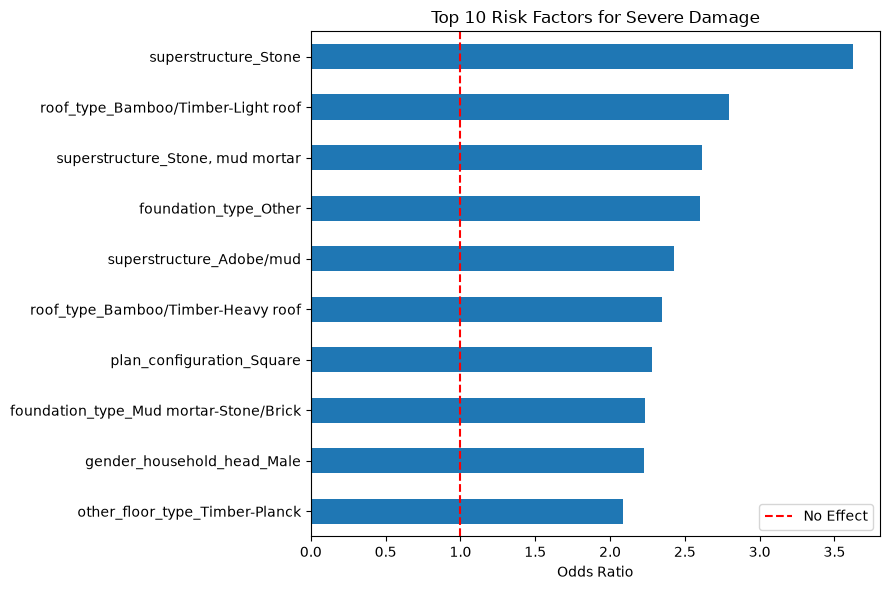

In [20]:
# Get feature names and coefficients
feature_names = model.named_steps['encoder'].get_feature_names_out()
coefficients = model.named_steps['classifier'].coef_[0]

# Create odds ratios
odds_ratios = pd.Series(np.exp(coefficients), index=feature_names).sort_values()

print("Top 10 features INCREASING odds of severe damage:")
print(odds_ratios.tail(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
odds_ratios.tail(10).plot(kind='barh', ax=ax)
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Risk Factors for Severe Damage')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect')
ax.legend()
plt.tight_layout()
plt.show()

Top 10 municipalities by damage rate:
           damage_rate  count
vdcmun_id                    
31            0.930199   4169
32            0.851117   7160
35            0.827145   3905
30            0.824201   6917
33            0.782464   6615
34            0.666979   2132
39            0.572344   7492
40            0.512444   6951
38            0.506425  11362
36            0.503972   5790


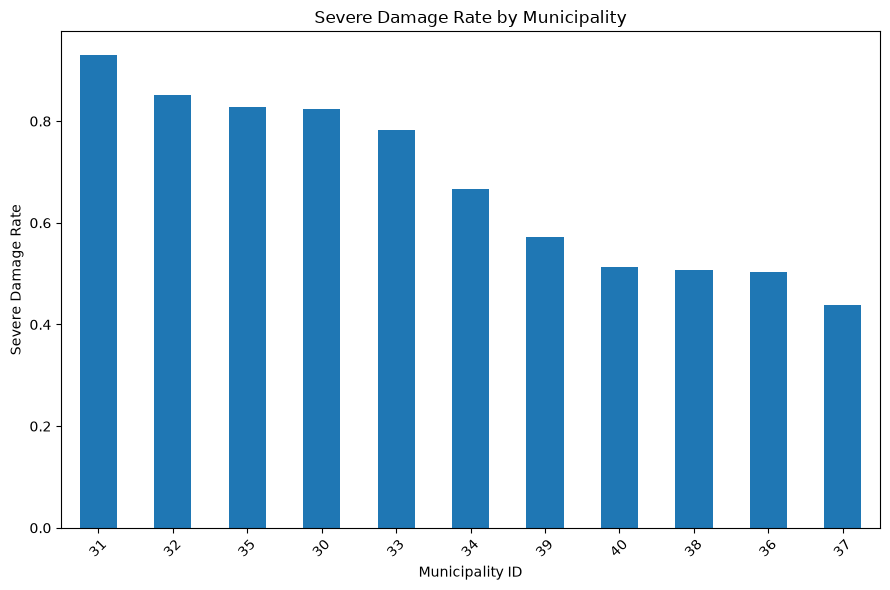

In [21]:
# Damage by municipality
damage_by_municipality = df.groupby('vdcmun_id')['severe_damage'].agg(['mean', 'count'])
damage_by_municipality.columns = ['damage_rate', 'count']
damage_by_municipality = damage_by_municipality.sort_values('damage_rate', ascending=False)

print("Top 10 municipalities by damage rate:")
print(damage_by_municipality.head(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
damage_by_municipality['damage_rate'].head(15).plot(kind='bar', ax=ax)
ax.set_xlabel('Municipality ID')
ax.set_ylabel('Severe Damage Rate')
ax.set_title('Severe Damage Rate by Municipality')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Top 10 features DECREASING odds of severe damage (protective factors):
superstructure_Brick, cement mortar    0.497356
foundation_type_RC                     0.505057
roof_type_RCC/RB/RBC                   0.692543
superstructure_RC, non-engineered      0.736740
superstructure_Timber                  0.774889
caste_household_Kumal                  0.783434
superstructure_Other                   0.784730
superstructure_Bamboo                  0.789878
other_floor_type_RCC/RB/RBC            0.804688
vdcmun_id                              0.810424
dtype: float64


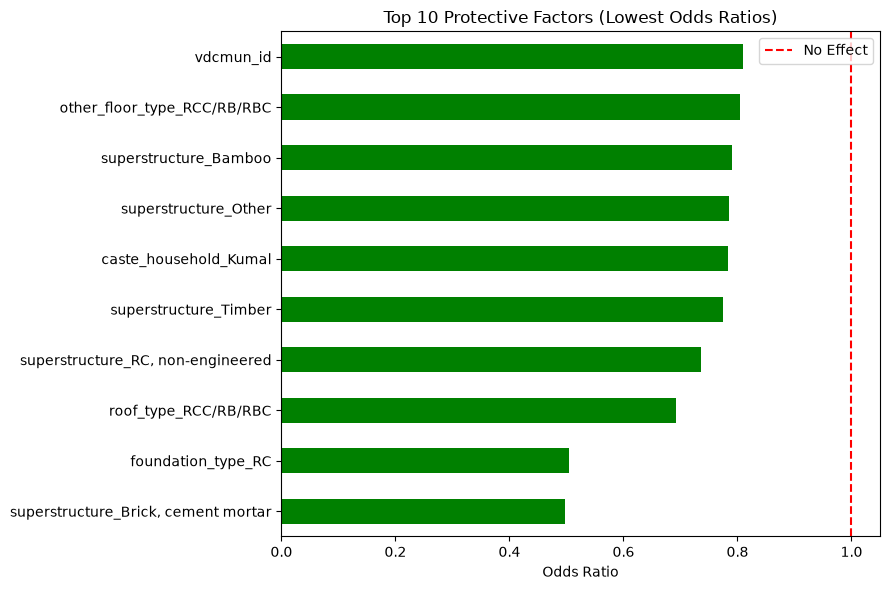

In [22]:
print("Top 10 features DECREASING odds of severe damage (protective factors):")
print(odds_ratios.head(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
odds_ratios.head(10).plot(kind='barh', ax=ax, color='green')
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Protective Factors (Lowest Odds Ratios)')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect')
ax.legend()
plt.tight_layout()
plt.show()

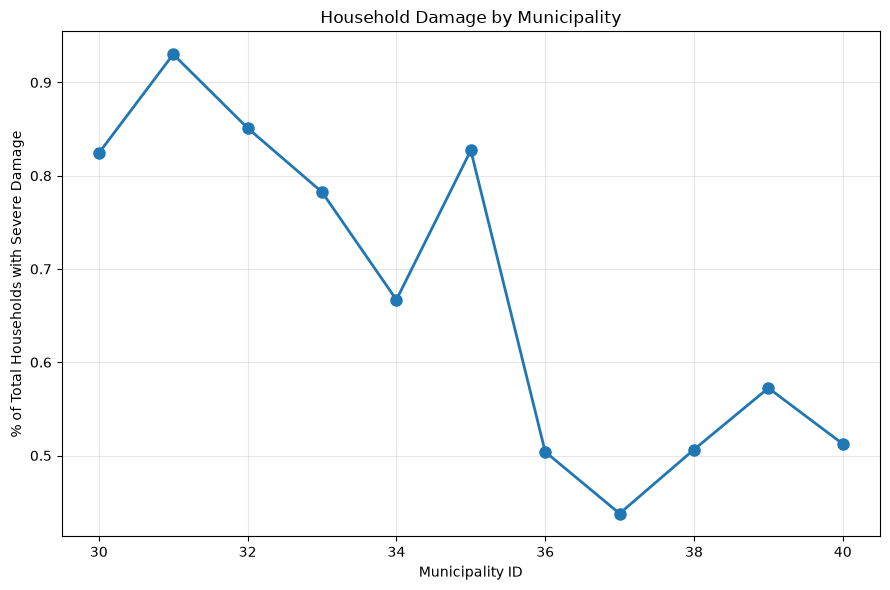

In [23]:
# Sort by municipality ID for line plot
damage_by_municipality_sorted = damage_by_municipality.sort_index()

# Create line plot
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(damage_by_municipality_sorted.index,
        damage_by_municipality_sorted['damage_rate'],
        marker='o', linewidth=2, markersize=8)
ax.set_xlabel('Municipality ID')
ax.set_ylabel('% of Total Households with Severe Damage')
ax.set_title('Household Damage by Municipality')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Calculate proportion of Gurung households by municipality
gurung_by_municipality = (
    df[df['caste_household'] == 'Gurung']
    .groupby('vdcmun_id')
    .size()
)

# Total households by municipality
total_by_municipality = df.groupby('vdcmun_id').size()

# Calculate proportion
damage_by_municipality['gurung_pct'] = (
    gurung_by_municipality / total_by_municipality
).fillna(0)

print("Gurung population by municipality:")
print(damage_by_municipality[['damage_rate', 'gurung_pct']].sort_values('gurung_pct', ascending=False))

Gurung population by municipality:
           damage_rate  gurung_pct
vdcmun_id                         
35            0.827145    0.826889
32            0.851117    0.387849
34            0.666979    0.385084
30            0.824201    0.338152
31            0.930199    0.326937
40            0.512444    0.246727
36            0.503972    0.143178
39            0.572344    0.097971
37            0.437789    0.050485
38            0.506425    0.049023
33            0.782464    0.011943


In [25]:
# Calculate proportion of Kumal households by municipality
kumal_by_municipality = (
    df[df['caste_household'] == 'Kumal']
    .groupby('vdcmun_id')
    .size()
)

# Calculate proportion (NaN will become 0)
damage_by_municipality['kumal_pct'] = (
    kumal_by_municipality / total_by_municipality
).fillna(0)

print("Kumal population by municipality:")
print(damage_by_municipality[['damage_rate', 'kumal_pct']].sort_values('kumal_pct', ascending=False))

# Show correlation
print(f"\nCorrelation between damage rate and Gurung population: {damage_by_municipality['damage_rate'].corr(damage_by_municipality['gurung_pct']):.3f}")
print(f"Correlation between damage rate and Kumal population: {damage_by_municipality['damage_rate'].corr(damage_by_municipality['kumal_pct']):.3f}")

Kumal population by municipality:
           damage_rate  kumal_pct
vdcmun_id                        
38            0.506425   0.100686
37            0.437789   0.048842
40            0.512444   0.036973
33            0.782464   0.029478
36            0.503972   0.003282
39            0.572344   0.000267
31            0.930199   0.000000
35            0.827145   0.000000
32            0.851117   0.000000
34            0.666979   0.000000
30            0.824201   0.000000

Correlation between damage rate and Gurung population: 0.570
Correlation between damage rate and Kumal population: -0.566
